In [1]:
# Stage 1: Data Loading & Feature Engineering
!pip install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from ucimlrepo import fetch_ucirepo

# 1. Load Data
real_estate = fetch_ucirepo(id=477)
X_raw = real_estate.data.features
y_raw = real_estate.data.targets
data = pd.concat([X_raw, y_raw], axis=1)

print("Dataset Shape:", data.shape)
print("Missing Values:\n", data.isnull().sum())
print("Duplicate Rows:", data.duplicated().sum())

# 2. Feature Engineering
data['transaction_year'] = data['X1 transaction date'].apply(lambda x: int(x))
data['transaction_month'] = data['X1 transaction date'].apply(lambda x: round((x - int(x)) * 12) + 1)
data['log_distance'] = np.log1p(data['X3 distance to the nearest MRT station'])
data['store_density'] = data['X4 number of convenience stores'] / (data['X3 distance to the nearest MRT station'] + 1)

Dataset Shape: (414, 7)
Missing Values:
 X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64
Duplicate Rows: 0


                                   Feature  Outliers Count
0                      X1 transaction date               0
1                             X2 house age               0
2   X3 distance to the nearest MRT station              37
3          X4 number of convenience stores               0
4                              X5 latitude               8
5                             X6 longitude              35
6               Y house price of unit area               3
7                         transaction_year               0
8                        transaction_month               0
9                             log_distance               2
10                           store_density              44


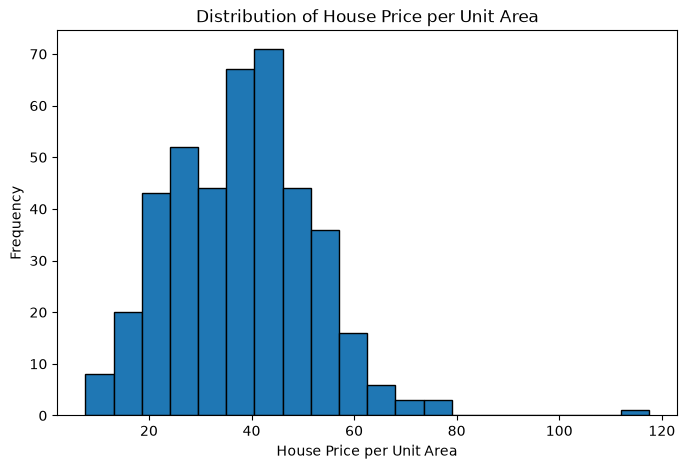

In [2]:
# Stage 1: Exploratory Data Analysis (EDA)

# 1. Outlier Detection (IQR)
numerical_cols = data.select_dtypes(include=np.number).columns
outlier_summary = []
for col in numerical_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
    outlier_summary.append({"Feature": col, "Outliers Count": len(outliers)})
print(pd.DataFrame(outlier_summary))

# 2. Target Distribution
plt.figure(figsize=(8, 5))
plt.hist(data['Y house price of unit area'], bins=20, edgecolor='black')
plt.title('Distribution of House Price per Unit Area')
plt.xlabel('House Price per Unit Area')
plt.ylabel('Frequency')
plt.show()

In [5]:

# Stage 2: Data Splitting & Scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feature_cols = ['X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 
                'X5 latitude', 'X6 longitude', 'transaction_year', 'transaction_month', 'log_distance', 'store_density']
X = data[feature_cols]
y = data['Y house price of unit area']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Training: {X_train.shape[0]}, Validation: {X_val.shape[0]}, Test: {X_test.shape[0]}")

Training: 289, Validation: 62, Test: 63


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feature_cols = ['X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'transaction_year', 'transaction_month', 'log_distance', 'store_density']
X = data[feature_cols]
y = data['Y house price of unit area']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

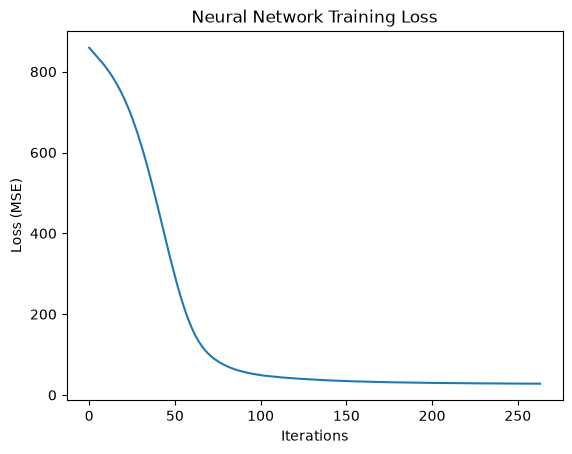

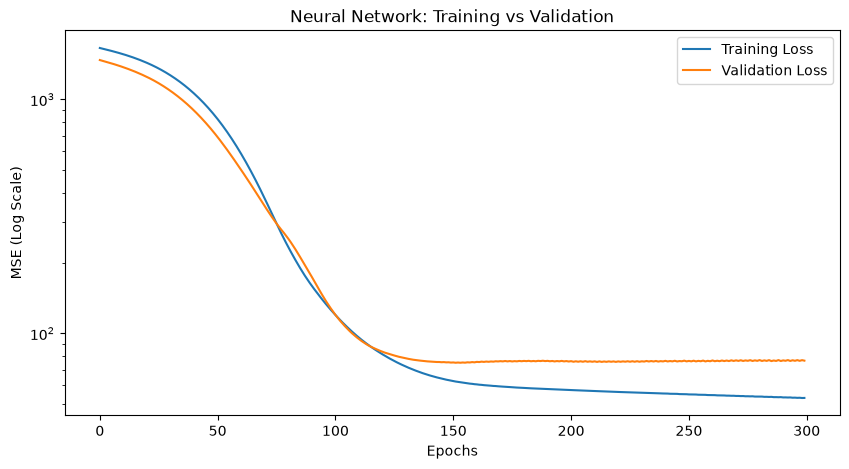

In [7]:
# (Shahad): Traditional Models & GridSearch
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

# 1. Linear Regression
lr = LinearRegression().fit(X_train_scaled, y_train)

# 2. Ridge
ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_train_scaled, y_train)

# 3. SVR
grid_svr = GridSearchCV(SVR(kernel='rbf'), {'C': [0.1, 1, 10, 100], 'epsilon': [0.01, 0.1, 0.5, 1.0]}, cv=5)
grid_svr.fit(X_train_scaled, y_train)

# 4. Random Forest
grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), {'n_estimators': [100, 200], 'max_depth': [10, 20]}, cv=5)
grid_rf.fit(X_train, y_train)

# 5. Gradient Boosting
grid_gb = GridSearchCV(GradientBoostingRegressor(random_state=42), {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1]}, cv=5)
grid_gb.fit(X_train, y_train)

# (Saja): Neural Network
from sklearn.neural_network import MLPRegressor
import matplotlib.pyplot as plt

mlp = MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', 
                   alpha=0.001, max_iter=2000, early_stopping=True, random_state=42)
mlp.fit(X_train_scaled, y_train)

# Plot Training Loss Curve
plt.plot(mlp.loss_curve_)
plt.title('Neural Network Training Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss (MSE)')
plt.show()

#Training & Validation Curves 


# (Saja): Train vs Validation Curves
from sklearn.neural_network import MLPRegressor
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

train_losses, val_losses = [], []
mlp_curve = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1, warm_start=True, random_state=42)

for epoch in range(1, 301):
    mlp_curve.fit(X_train_scaled, y_train)
    train_losses.append(mean_squared_error(y_train, mlp_curve.predict(X_train_scaled)))
    val_losses.append(mean_squared_error(y_val, mlp_curve.predict(X_val_scaled)))

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Neural Network: Training vs Validation')
plt.xlabel('Epochs')
plt.ylabel('MSE (Log Scale)')
plt.yscale('log')
plt.legend()
plt.show()


In [9]:
# (Saja): Final Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {'Linear Regression': (lr, True), 'Ridge': (ridge, True), 
          'SVR': (grid_svr, True), 'Random Forest': (grid_rf, False), 
          'Gradient Boosting': (grid_gb, False), 'Neural Network': (mlp, True)}

for name, (model, needs_scaling) in models.items():
    X_used = X_test_scaled if needs_scaling else X_test
    y_pred = model.predict(X_used)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name:<20} | MAE: {mae:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}")

Linear Regression    | MAE: 4.3488 | MSE: 41.7295 | RMSE: 6.4598 | R²: 0.7498
Ridge                | MAE: 4.3461 | MSE: 41.6439 | RMSE: 6.4532 | R²: 0.7503
SVR                  | MAE: 4.1118 | MSE: 36.3984 | RMSE: 6.0331 | R²: 0.7817
Random Forest        | MAE: 3.8044 | MSE: 24.4215 | RMSE: 4.9418 | R²: 0.8536
Gradient Boosting    | MAE: 3.8882 | MSE: 25.1650 | RMSE: 5.0165 | R²: 0.8491
Neural Network       | MAE: 4.5550 | MSE: 34.9646 | RMSE: 5.9131 | R²: 0.7903
